# Finding an object in an image with a mask

A grayscale image is just a matrix: each element is the brightness of one pixel.
We will build an image, pick out a bright object with a **mask** (a True/False matrix of the same shape), and use that mask to find where the object is.

In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(310)

## Make a synthetic image

`np.mgrid` gives two matrices holding the row and column number of every pixel. With those we can write the disk as an equation, $(r - r_0)^2 + (c - c_0)^2 \le R^2$, and test every pixel at once.

In [2]:
n_rows, n_cols = 120, 160
r0, c0, R = 70, 105, 14                      # true center (row, col) and radius

rows, cols = np.mgrid[0:n_rows, 0:n_cols]
disk = (rows - r0)**2 + (cols - c0)**2 <= R**2

img = 0.15 + 0.05 * rng.standard_normal((n_rows, n_cols))   # dark, noisy background
img = img + 0.6 * disk                                       # bright disk on top

print("image shape:", img.shape)
print(np.round(img[:3, :4], 2))              # the top-left corner is just numbers

image shape: (120, 160)
[[0.16 0.14 0.21 0.12]
 [0.12 0.25 0.14 0.17]
 [0.11 0.21 0.12 0.07]]


`imshow` draws the matrix with row 0 at the **top**, so the vertical axis is the row index and the horizontal axis is the column index.

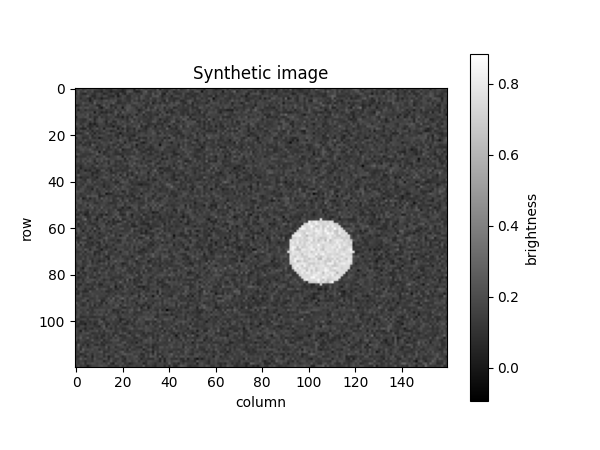

In [3]:
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(img, cmap="gray")
fig.colorbar(im, ax=ax, label="brightness")
ax.set_xlabel("column")
ax.set_ylabel("row")
ax.set_title("Synthetic image");

## Choose a threshold

A histogram of pixel values shows two groups, background and object. Any threshold in the gap between them will separate the two.

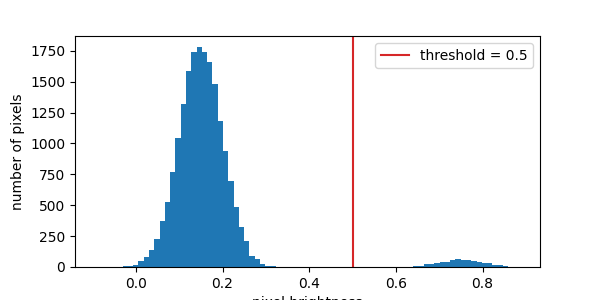

In [4]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(img.ravel(), bins=80)
threshold = 0.5
ax.axvline(threshold, color="C3", label=f"threshold = {threshold}")
ax.set_xlabel("pixel brightness")
ax.set_ylabel("number of pixels")
ax.legend();

## Build the mask

Comparing the whole matrix to a number gives a boolean matrix of the same shape: `True` where the pixel is bright, `False` elsewhere.

mask shape: (120, 160)  dtype: bool
bright pixels: 613


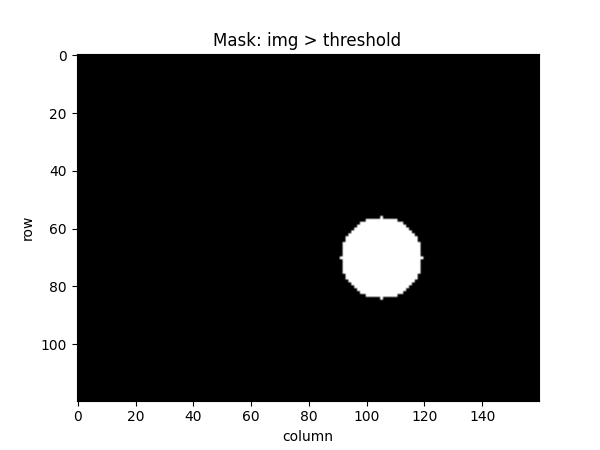

In [5]:
mask = img > threshold
print("mask shape:", mask.shape, " dtype:", mask.dtype)
print("bright pixels:", mask.sum())          # True counts as 1

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(mask, cmap="gray")
ax.set_xlabel("column")
ax.set_ylabel("row")
ax.set_title("Mask: img > threshold");

The mask can also index the image directly. `img[mask]` returns only the object's pixels, which is handy for measuring things like size and brightness.

In [6]:
print("object area (pixels):", mask.sum(), " expected about", round(np.pi * R**2))
print("mean object brightness:", img[mask].mean().round(3))
print("mean background brightness:", img[~mask].mean().round(3))

object area (pixels): 613  expected about 616
mean object brightness: 0.75
mean background brightness: 0.15


## Locate the object

`np.nonzero(mask)` returns the row and column index of every `True` pixel. The smallest and largest of each give a **bounding box**.

In [7]:
r_idx, c_idx = np.nonzero(mask)
r_min, r_max = r_idx.min(), r_idx.max()
c_min, c_max = c_idx.min(), c_idx.max()
print(f"rows {r_min} to {r_max}, columns {c_min} to {c_max}")

rows 56 to 84, columns 91 to 119


The **centroid** is the average location of the masked pixels, which is just the mean of those row and column indices.

In [8]:
r_cen, c_cen = r_idx.mean(), c_idx.mean()
print(f"centroid: row {r_cen:.2f}, col {c_cen:.2f}")
print(f"true:     row {r0}, col {c0}")

centroid: row 70.00, col 105.00
true:     row 70, col 105


## Overlay the result

When plotting on an image, x is the column and y is the row, so the order flips from `(row, col)` to `(col, row)`.

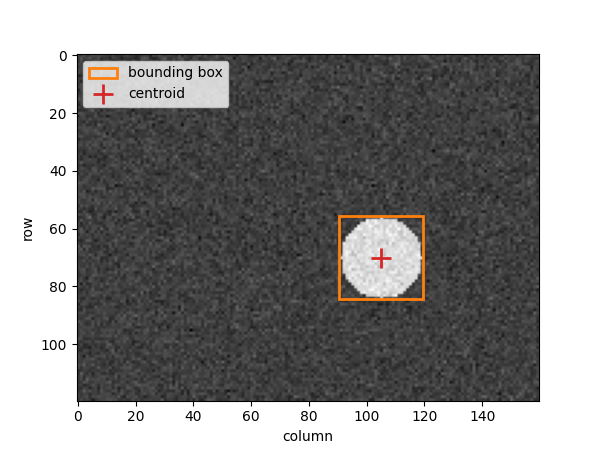

In [9]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(img, cmap="gray")
box = Rectangle((c_min - 0.5, r_min - 0.5), c_max - c_min + 1, r_max - r_min + 1,
                fill=False, edgecolor="C1", linewidth=2, label="bounding box")
ax.add_patch(box)
ax.plot(c_cen, r_cen, "+", color="C3", markersize=14, markeredgewidth=2, label="centroid")
ax.set_xlabel("column")
ax.set_ylabel("row")
ax.legend(loc="upper left");

**Try it:** drop the threshold to 0.3 and rerun. A few noisy background pixels sneak into the mask, which stretches the bounding box far more than it moves the centroid.